# DreamerV3 Restart With A 95% BO Target

This notebook launches a fresh DreamerV3 run from scratch for the Haber-Bosch case. The BO solution is used only as an external benchmark and a convergence target. It is not seeded into replay.

The training intervention is replay-focused rather than reward-focused: keep a smaller replay set, preserve a fixed elite slice of the best episodes found so far, and combine it with a recent slice so the policy stays grounded in its latest behavior.

In [1]:
from __future__ import annotations

import importlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import dreamerv3_haberbosch_helpers as dreamer_helpers

hb = importlib.reload(dreamer_helpers)
hb.set_plot_style()

WORKSPACE_DIR = hb.WORKSPACE_DIR
RUN_LOGDIR = WORKSPACE_DIR / "runs" / "dreamerv3_haber_bosch_target95_elite_replay"
SEED = 7

In [2]:
BO_REFERENCE = {
    "reward": 2712.651793,
    "normalized_action": np.array([
        -0.6127335418989747,
        0.08136597881754437,
        0.6577094487733803,
        1.0,
        1.0,
        1.0,
        -1.0,
    ], dtype=np.float32),
}

TARGET_FRACTION = 0.95
TARGET_REWARD = TARGET_FRACTION * BO_REFERENCE["reward"]
MAX_EPISODES = 1600
EPISODE_BLOCK = 100
CONVERGENCE_WINDOW = 50
REPLAY_KEEP_TOP = 64
REPLAY_KEEP_RECENT = 128
REPLAY_SIZE = REPLAY_KEEP_TOP + REPLAY_KEEP_RECENT

pd.DataFrame([
    {
        "bo_reward": BO_REFERENCE["reward"],
        "target_fraction": TARGET_FRACTION,
        "target_reward": TARGET_REWARD,
        "max_episodes": MAX_EPISODES,
        "episode_block": EPISODE_BLOCK,
        "replay_size": REPLAY_SIZE,
        "replay_keep_top": REPLAY_KEEP_TOP,
        "replay_keep_recent": REPLAY_KEEP_RECENT,
    }
])

,bo_reward,target_fraction,target_reward,max_episodes,episode_block,replay_size,replay_keep_top,replay_keep_recent
0,2712.651793,0.95,2577.019203,1600,100,192,64,128


In [3]:
def evaluate_normalized_action(environment, action: np.ndarray) -> dict[str, float]:
    environment.reset()
    _, reward, terminated, truncated, info = environment.step(action)
    row = {
        "reward": float(reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
    }
    scaled = np.asarray(info.get("scaled_action", np.zeros_like(action)), dtype=np.float64)
    row.update({f"a{index}": float(action[index - 1]) for index in range(1, 8)})
    row.update({f"a{index}_physical": float(scaled[index - 1]) for index in range(1, 8)})
    for name, value in info.items():
        if name == "scaled_action":
            continue
        if isinstance(value, (int, float, np.integer, np.floating, bool)):
            row[name] = float(value) if not isinstance(value, bool) else bool(value)
    return row

preflight = hb.build_preflight_frame()
display(preflight)
if not preflight["ok"].all():
    missing = preflight.loc[~preflight["ok"], "item"].tolist()
    raise RuntimeError(f"Preflight failed for: {missing}")

env = hb.make_haber_bosch_env()
try:
    smoke_test = hb.run_smoke_test(env)
    bo_reference_row = evaluate_normalized_action(env, BO_REFERENCE["normalized_action"])
finally:
    env.close()

display(smoke_test.to_frame(name="value"))
baseline_frame = pd.DataFrame([bo_reference_row])
baseline_frame["target_reward"] = TARGET_REWARD
baseline_frame["target_gap"] = baseline_frame["target_reward"] - baseline_frame["reward"]
display(
    baseline_frame[[
        "reward",
        "target_reward",
        "target_gap",
        "nh3_kg_per_s",
        "power_kw",
        "revenue_per_h",
        "energy_cost_per_h",
    ]]
)

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


,reward,target_reward,target_gap,nh3_kg_per_s,power_kw,revenue_per_h,energy_cost_per_h
0,2712.651793,2577.019203,-135.63259,2.4751,2814.232893,4455.180451,1742.528658


## Restart Configuration

This run starts from scratch in a new log directory. The replay policy is the main intervention:

- keep a smaller active replay set
- always reserve space for the top-reward episodes found so far
- keep a recent slice so the policy does not drift onto a stale elite-only distribution

The single-step episode design means `replay_size` is a practical proxy for the number of episodes kept active in replay.

In [4]:
TRAIN_CFG = hb.DreamerExperimentConfig()
TRAIN_CFG.seed = SEED
TRAIN_CFG.logdir = RUN_LOGDIR
TRAIN_CFG.seed_logdir_from = None
TRAIN_CFG.resume_from_checkpoint = None
TRAIN_CFG.reset_existing_run = True
TRAIN_CFG.target_episodes = EPISODE_BLOCK
TRAIN_CFG.prefill_steps = 64
TRAIN_CFG.replay_size = REPLAY_SIZE
TRAIN_CFG.replay_policy = "elite_recent"
TRAIN_CFG.replay_keep_top_episodes = REPLAY_KEEP_TOP
TRAIN_CFG.replay_keep_recent_episodes = REPLAY_KEEP_RECENT
TRAIN_CFG.eval_every_steps = EPISODE_BLOCK
TRAIN_CFG.log_every_steps = 25
TRAIN_CFG.eval_episodes = 5
TRAIN_CFG.train_ratio = 12.0
TRAIN_CFG.episode_report_frequency = 10

QUICK_CFG = hb.build_quick_validation_config(TRAIN_CFG)

config_view = pd.DataFrame([hb.serialize_experiment_config(TRAIN_CFG)]).T.reset_index()
config_view.columns = ["parameter", "value"]
display(config_view)
display(Markdown(
    f"**Training objective:** push the rolling {CONVERGENCE_WINDOW}-episode mean to at least **{TARGET_REWARD:.3f}**, which is 95% of the BO reward **{BO_REFERENCE['reward']:.3f}**."
))

,parameter,value
0,repo_url,https://github.com/NM512/dreamerv3-torch.git
1,seed,7
2,repo_dir,/Users/campatzis/Documents/Research/third_part...
3,logdir,/Users/campatzis/Documents/Research/runs/dream...
4,seed_logdir_from,None
5,target_episodes,100
6,prefill_steps,64
7,replay_size,192
8,replay_policy,elite_recent
9,replay_keep_top_episodes,64


**Training objective:** push the rolling 50-episode mean to at least **2577.019**, which is 95% of the BO reward **2712.652**.

In [5]:
backend_preflight = hb.preflight_dreamer_agent(TRAIN_CFG)
display(pd.DataFrame([{key: value for key, value in backend_preflight.items() if key != "config_namespace"}]))

/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


No resume checkpoint selected. Training starts from scratch.
Encoder CNN shapes: {}
Encoder MLP shapes: {'state': (5,)}
Decoder CNN shapes: {}
Decoder MLP shapes: {'state': (5,)}


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:754: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Optimizer model_opt has 498181 variables.
Optimizer actor_opt has 67854 variables.
Optimizer value_opt has 98943 variables.


,dreamer_preflight,device,num_actions,patch_report,tensorboard_dir,checkpoint_dir,resume_path
0,ok,mps,7,{'networks.py': False},/Users/campatzis/Documents/Research/runs/dream...,/Users/campatzis/Documents/Research/runs/dream...,None


In [6]:
def load_train_metrics(logdir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    metrics = hb.load_metrics_frame(logdir)
    train = metrics.loc[metrics["train_return"].notna()].copy()
    train = train.sort_values("step").reset_index(drop=True)
    return metrics, train

def summarize_target_progress(train_df: pd.DataFrame, target_reward: float, window: int) -> tuple[dict[str, float | int | bool], pd.DataFrame]:
    if train_df.empty:
        empty_summary = {
            "episodes": 0,
            "best_train_reward": float('nan'),
            "gap_to_target": float('nan'),
            "latest_reward": float('nan'),
            "rolling_mean": float('nan'),
            "rolling_hit_rate": float('nan'),
            "target_hits": 0,
            "converged": False,
        }
        return empty_summary, train_df.copy()

    summary_frame = train_df.copy()
    summary_frame["target_hit"] = summary_frame["train_return"] >= target_reward
    summary_frame["rolling_mean"] = summary_frame["train_return"].rolling(window, min_periods=1).mean()
    summary_frame["rolling_hit_rate"] = summary_frame["target_hit"].rolling(window, min_periods=1).mean()

    best_row = summary_frame.loc[int(summary_frame["train_return"].idxmax())].copy()
    last_row = summary_frame.iloc[-1].copy()
    summary = {
        "episodes": int(len(summary_frame)),
        "best_train_reward": float(best_row["train_return"]),
        "gap_to_target": float(target_reward - best_row["train_return"]),
        "latest_reward": float(last_row["train_return"]),
        "rolling_mean": float(last_row["rolling_mean"]),
        "rolling_hit_rate": float(last_row["rolling_hit_rate"]),
        "target_hits": int(summary_frame["target_hit"].sum()),
        "converged": bool(last_row["rolling_mean"] >= target_reward),
    }
    return summary, summary_frame

def summarize_replay_selection(logdir: Path, config, target_reward: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    replay_frame = hb.inspect_replay_inventory(logdir / "train_eps", config, target_reward=target_reward)
    selected = replay_frame.loc[replay_frame["selected_for_replay"]].copy()
    return replay_frame, selected

In [7]:
RUN_QUICK_VALIDATION = False

if RUN_QUICK_VALIDATION:
    quick_result = hb.run_dreamer_training(QUICK_CFG, run_training=True)
    quick_metrics, quick_train = load_train_metrics(QUICK_CFG.logdir)
    quick_summary, quick_train = summarize_target_progress(quick_train, TARGET_REWARD, window=12)
    display(pd.DataFrame([quick_result.get("after", quick_result)]))
    display(pd.DataFrame([quick_summary]))
    hb.plot_training_diagnostics(quick_metrics)
else:
    print("Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.")

Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.


## Full Training Loop

This loop trains from scratch in 100-episode blocks. After each block it checks whether the rolling mean has reached the 95% BO target and inspects the replay selection that would stay active under the elite-plus-recent policy.

In [8]:
RUN_FRESH_TRAINING = True
STOP_ON_TARGET_CONVERGENCE = True

block_history: list[dict[str, float | int | bool]] = []

if RUN_FRESH_TRAINING:
    for block_target in range(EPISODE_BLOCK, MAX_EPISODES + 1, EPISODE_BLOCK):
        TRAIN_CFG.target_episodes = block_target
        TRAIN_CFG.reset_existing_run = block_target == EPISODE_BLOCK

        result = hb.run_dreamer_training(TRAIN_CFG, run_training=True)
        metrics_df, train_df = load_train_metrics(TRAIN_CFG.logdir)
        target_summary, train_df = summarize_target_progress(train_df, TARGET_REWARD, CONVERGENCE_WINDOW)
        replay_frame, replay_selected = summarize_replay_selection(TRAIN_CFG.logdir, TRAIN_CFG, TARGET_REWARD)

        row = {
            "episode_budget": int(block_target),
            "completed_episodes": int(target_summary["episodes"]),
            "best_train_reward": float(target_summary["best_train_reward"]),
            "gap_to_target": float(target_summary["gap_to_target"]),
            "latest_reward": float(target_summary["latest_reward"]),
            "rolling_mean": float(target_summary["rolling_mean"]),
            "rolling_hit_rate": float(target_summary["rolling_hit_rate"]),
            "target_hits": int(target_summary["target_hits"]),
            "selected_replay_rows": int(len(replay_selected)),
            "selected_replay_best_reward": float(replay_selected["reward"].max()) if not replay_selected.empty else float('nan'),
            "selected_target_hits": int(replay_selected["meets_target"].fillna(False).sum()) if not replay_selected.empty else 0,
            "converged": bool(target_summary["converged"]),
        }
        block_history.append(row)
        display(pd.DataFrame([row]))

        if STOP_ON_TARGET_CONVERGENCE and row["converged"]:
            print(
                f"Stopping early: the rolling {CONVERGENCE_WINDOW}-episode mean reached {row['rolling_mean']:.3f}, which is at or above the 95% BO target {TARGET_REWARD:.3f}."
            )
            break
else:
    print("Set RUN_FRESH_TRAINING = True to archive any prior run in this logdir and start the fresh targeted training loop.")

/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch
No resume checkpoint selected. Training starts from scratch.
Logdir /Users/campatzis/Documents/Research/runs/dreamerv3_haber_bosch_target95_elite_replay
Create envs.
Action Space Box(-1.0, 1.0, (7,), float32)
Prefill dataset (64 steps).
[Dreamer][Episode 10] Reward=-1510.44 | AvgReward=-22.89 | BestReward=1804.67 | NH3=1.0676 kg/s | Power=2207.77 kW | Revenue=1921.69 $/h | EnergyCost=3432.13 $/h | EnvSteps=0 | Updates=0 | DatasetSize=10 | Device=mps | ElapsedMin=1.0
[Dreamer][Episode 20] Reward=808.87 | AvgReward=-1862.43 | BestReward=1804.67 | NH3=2.0208 kg/s | Power=2215.72 kW | Revenue=3637.36 $/h | EnergyCost=2828.48 $/h | EnvSteps=0 | Updates=0 | DatasetSize=20 | Device=mps | ElapsedMin=2.0
[Dreamer][E

/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:754: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[64] log_reward 1846.1 / log_nh3_kg_per_s 2.1 / log_nh3_ton_per_h 7.5 / log_power_kw 2112.9 / log_revenue_per_h 3750.9 / log_energy_cost_per_h 1904.8 / log_a1_normalized 0.9 / log_a1_physical 3.5 / log_a2_normalized -0.0 / log_a2_physical 54.5 / log_a3_normalized -0.4 / log_a3_physical 88.0 / log_a4_normalized -0.7 / log_a4_physical 172.8 / log_a5_normalized 0.9 / log_a5_physical 490.5 / log_a6_normalized -1.0 / log_a6_physical -29.3 / log_a7_normalized 0.9 / log_a7_physical 0.1 / eval_return 1596.6 / eval_length 1.0 / eval_episodes 5.0
moviepy is installed, but can't import moviepy.editor. Some packages could be missing [imageio, requests]
Start training.


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:323: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):


[0] model_loss 40.3 / model_grad_norm 94.9 / state_loss 32.3 / reward_loss 5.2 / cont_loss 0.5 / kl_free 1.0 / dyn_scale 0.5 / rep_scale 0.1 / dyn_loss 3.8 / rep_loss 3.8 / kl 3.8 / prior_ent 43.2 / post_ent 41.3 / normed_target_mean -0.0 / normed_target_std 0.0 / normed_target_min -0.1 / normed_target_max -0.0 / EMA_005 -0.0 / EMA_095 -0.0 / value_mean -0.0 / value_std 0.0 / value_min -0.0 / value_max -0.0 / target_mean -0.1 / target_std 0.0 / target_min -0.1 / target_max -0.0 / imag_reward_mean -0.1 / imag_reward_std 0.0 / imag_reward_min -0.1 / imag_reward_max -0.0 / imag_action_mean 0.0 / imag_action_std 0.7 / imag_action_min -1.0 / imag_action_max 1.0 / actor_entropy 9.0 / actor_loss 0.0 / actor_grad_norm 0.0 / value_loss 8.2 / value_grad_norm 5.8 / update_count 100.0 / fps 0.0
[Dreamer][Episode 70] Reward=651.84 | AvgReward=419.82 | BestReward=2354.85 | NH3=1.9352 kg/s | Power=3046.83 kW | Revenue=3483.28 $/h | EnergyCost=2831.44 $/h | EnvSteps=70 | Updates=100 | DatasetSize=70 |

,episode_budget,completed_episodes,best_train_reward,gap_to_target,latest_reward,rolling_mean,rolling_hit_rate,target_hits,selected_replay_rows,selected_replay_best_reward,selected_target_hits,converged
0,100,264,2711.016846,-133.997642,-2092.904053,-3027.209422,0.06,17,161,2711.016846,17,False


... (54 outputs left out)

[1464] model_loss 1.2 / model_grad_norm 3.9 / state_loss 0.1 / reward_loss 0.5 / cont_loss 0.0 / kl_free 1.0 / dyn_scale 0.5 / rep_scale 0.1 / dyn_loss 1.0 / rep_loss 1.0 / kl 0.8 / prior_ent 34.1 / post_ent 30.2 / normed_target_mean 4.6 / normed_target_std 0.3 / normed_target_min 3.4 / normed_target_max 5.0 / EMA_005 746.2 / EMA_095 808.6 / value_mean 1.1 / value_std 0.0 / value_min 1.1 / value_max 1.2 / target_mean 1030.6 / target_std 20.0 / target_min 960.1 / target_max 1058.9 / imag_reward_mean 859.9 / imag_reward_std 388.9 / imag_reward_min 0.2 / imag_reward_max 1058.2 / imag_action_mean 0.1 / imag_action_std 0.8 / imag_action_min -1.0 / imag_action_max 1.0 / actor_entropy 7.0 / actor_loss -12.4 / actor_grad_norm 0.1 / value_loss 6.8 / value_grad_norm 7.6 / update_count 1.0 / fps 0.0
[Dreamer][Episode 10] Reward=2485.77 | AvgReward=2521.93 | BestReward=2596.14 | NH3=2.3805 kg/s | Power=2973.81 kW | Revenue=4284.86 $/h | EnergyCost=1799.09 $/h | EnvSteps=1474 | Updates=1 | DatasetS

,episode_budget,completed_episodes,best_train_reward,gap_to_target,latest_reward,rolling_mean,rolling_hit_rate,target_hits,selected_replay_rows,selected_replay_best_reward,selected_target_hits,converged
0,1500,1664,2711.016846,-133.997642,1941.223999,2351.45695,0.06,139,189,2711.016846,75,False


/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch
No resume checkpoint selected. Training starts from scratch.
Target episode budget already reached for this logdir.


,episode_budget,completed_episodes,best_train_reward,gap_to_target,latest_reward,rolling_mean,rolling_hit_rate,target_hits,selected_replay_rows,selected_replay_best_reward,selected_target_hits,converged
0,1600,1664,2711.016846,-133.997642,1941.223999,2351.45695,0.06,139,189,2711.016846,75,False


,logdir,target_reward,best_train_reward,gap_to_target,latest_reward,rolling_mean,rolling_hit_rate,target_hits,selected_replay_rows,selected_replay_target_hits,converged
0,/Users/campatzis/Documents/Research/runs/dream...,2577.019203,2711.016846,-133.997642,1941.223999,2351.45695,0.06,139,189,75,False


,step,train_return,rolling_mean,rolling_hit_rate
1614,1615,2530.807861,2378.388633,0.12
1615,1616,2405.284424,2386.699966,0.12
1616,1617,2578.587402,2386.737813,0.14
1617,1618,2454.171875,2391.931948,0.14
1618,1619,2295.306396,2391.048926,0.14
1619,1620,2105.256836,2380.694648,0.12
1620,1621,2383.451172,2379.195425,0.12
1621,1622,2509.223877,2381.530273,0.12
1622,1623,2574.176514,2392.020913,0.12
1623,1624,2528.887939,2391.727896,0.12


,episode,reward,transitions,recent_rank,reward_rank,selected_for_replay,meets_target
0,20260427T125518-4bbd359147d54b8b9be29594330cdc...,2711.016846,1,1447,1,True,True
1,20260427T133813-68637d1af51b403cbdfd97277c2676...,2700.789795,1,1308,2,True,True
2,20260427T132902-5523af03c1f448da814d5125df602d...,2699.919434,1,1316,3,True,True
3,20260427T130111-c631edd775de4e34867872c527146b...,2699.285156,1,1421,4,True,True
4,20260427T162939-a0d8851c40c74b258601604bbd4c0f...,2697.060547,1,1015,5,True,True
5,20260427T165409-9d9f20455bbb416d915f8702355f6b...,2696.078125,1,985,6,True,True
6,20260427T134904-528dc573e61040d6bc3e0d9c865e63...,2695.196533,1,1295,7,True,True
7,20260427T161839-b003b991aa5842cc8a25888326d9a2...,2693.303223,1,1038,8,True,True
8,20260427T121404-00c2a4c0a9f645e7afcda94bef9cf4...,2691.017578,1,1581,9,True,True
9,20260427T164828-a20ecadecb9b4684bed076c802fc10...,2688.053955,1,999,10,True,True


(<Figure size 2160x1200 with 4 Axes>,
 array([<Axes: title={'center': 'Reward Progress'}, xlabel='Environment steps', ylabel='Reward'>,
        <Axes: title={'center': 'Process Economics'}, xlabel='Environment steps', ylabel='Value'>,
        <Axes: title={'center': 'System Load and Training Volume'}, xlabel='Environment steps', ylabel='Value'>,
        <Axes: title={'center': 'Optimization Diagnostics'}, xlabel='Environment steps', ylabel='Value'>],
       dtype=object))

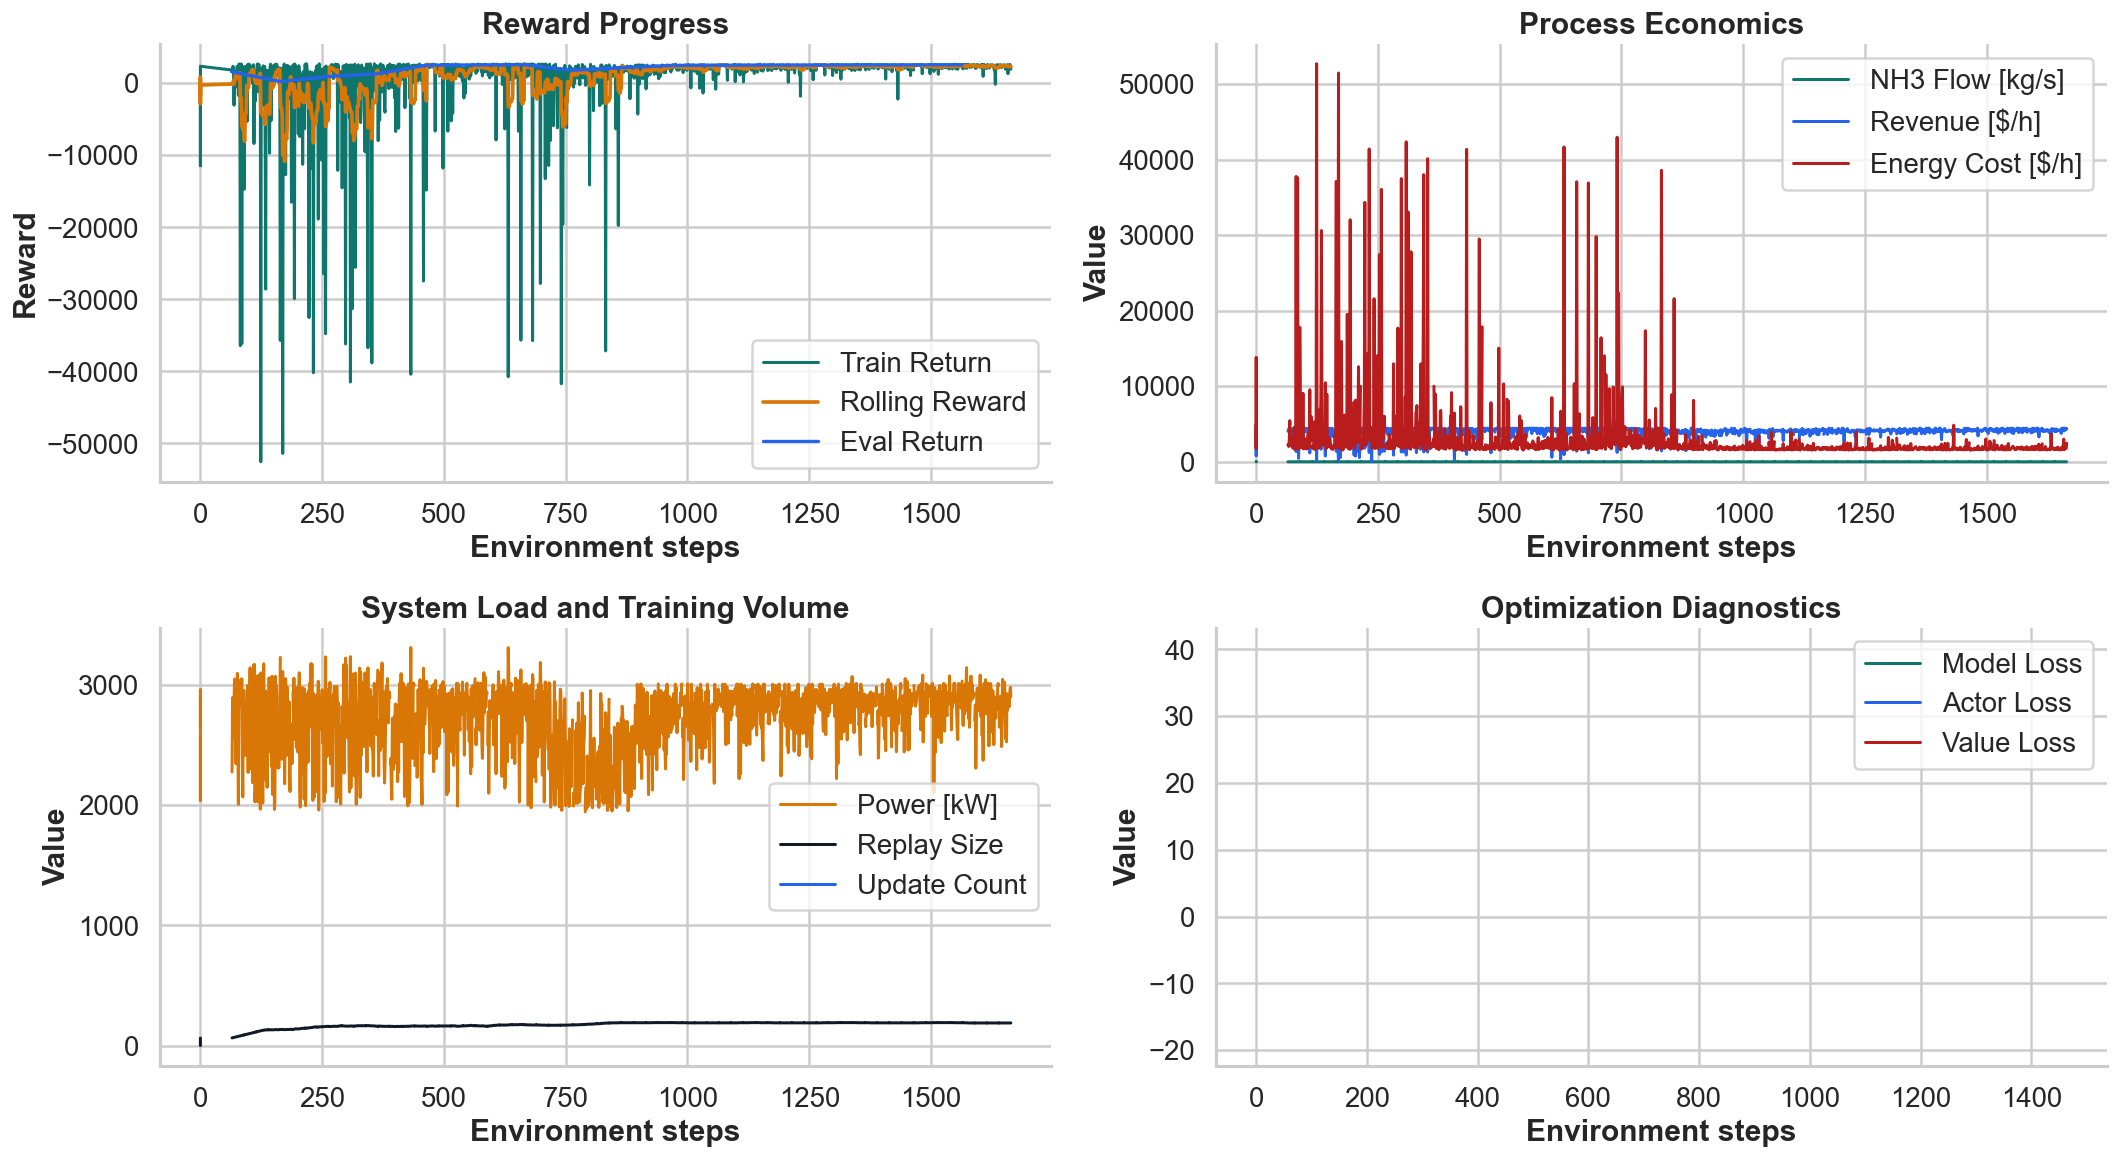

In [9]:
analysis_metrics, analysis_train = load_train_metrics(TRAIN_CFG.logdir)
analysis_summary, analysis_train = summarize_target_progress(analysis_train, TARGET_REWARD, CONVERGENCE_WINDOW)
replay_inventory, replay_selected = summarize_replay_selection(TRAIN_CFG.logdir, TRAIN_CFG, TARGET_REWARD)

summary_frame = pd.DataFrame([
    {
        "logdir": str(TRAIN_CFG.logdir),
        "target_reward": TARGET_REWARD,
        "best_train_reward": float(analysis_summary["best_train_reward"]),
        "gap_to_target": float(analysis_summary["gap_to_target"]),
        "latest_reward": float(analysis_summary["latest_reward"]),
        "rolling_mean": float(analysis_summary["rolling_mean"]),
        "rolling_hit_rate": float(analysis_summary["rolling_hit_rate"]),
        "target_hits": int(analysis_summary["target_hits"]),
        "selected_replay_rows": int(len(replay_selected)),
        "selected_replay_target_hits": int(replay_selected["meets_target"].fillna(False).sum()) if not replay_selected.empty else 0,
        "converged": bool(analysis_summary["converged"]),
    }
])
display(summary_frame)
display(analysis_train.tail(CONVERGENCE_WINDOW)[["step", "train_return", "rolling_mean", "rolling_hit_rate"]])
display(replay_selected.head(20))
hb.plot_training_diagnostics(analysis_metrics)

## Interpretation Guide

Use the final summary with three questions in mind:

1. Did the best reward clear the 95% BO target?
2. Did the rolling mean clear the target, or did the policy only touch it intermittently?
3. Does the selected replay set contain multiple target-hitting episodes, or is the run still depending on isolated outliers?